# Dynamic Regression Models for Reliance Industries

## Objective
To implement and compare four dynamic regression models
for forecasting Reliance Industries' stock closing price.

## Models
1. Multiple Linear Regression
2. Dynamic Regression with AR(1) Errors
3. Dynamic Regression with ARIMA Errors
4. Dynamic Regression with Lagged Predictors

In [2]:
%pip install pandas numpy matplotlib scikit-learn statsmodels

Defaulting to user installation because normal site-packages is not writeable
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   -------------------------- ------------- 7.1/10.7 MB 35.9 MB/s eta 0:00:01
   ---------------------------------------- 10.7/10.7 MB 25.0 MB/s eta 0:00:00
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   --------------------------------- ------ 10.5/12.6 MB 49.7 MB/s eta 0:00:01
   ---------------------------------------  12.3/12.6 MB 49.0 MB/s eta 0:00:01
   ---------------------------------------- 12.6/12.6 MB 26.8 MB/s eta 0:00:00
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------  9.2/9.3 MB 47.9 MB/s eta 0:00:01
   ---------------------------------------- 9.3


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.statespace.sarimax import SARIMAX

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
import pandas as pd
df = pd.read_csv("../data/raw/RELIANCE.csv")

df.head()

,index,Date,Adj Close,Close,High,Low,Open,Volume
0,0,2015-01-01,189.125381,202.959000,203.896194,201.987518,202.593277,2963643
1,1,2015-01-02,188.624817,202.421829,204.821960,202.136108,203.004715,7331366
2,2,2015-01-05,186.558685,200.204575,203.644760,199.804550,202.296112,10103941
3,3,2015-01-06,178.091827,191.118393,199.553116,190.181198,198.867371,18627980
4,4,2015-01-07,181.968475,195.278610,196.307236,191.324127,191.346985,20720312


In [6]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape:
(2911, 8)

Column Information:
<class 'pandas.DataFrame'>
RangeIndex: 2911 entries, 0 to 2910
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   index      2911 non-null   int64  
 1   Date       2911 non-null   str    
 2   Adj Close  2911 non-null   float64
 3   Close      2911 non-null   float64
 4   High       2911 non-null   float64
 5   Low        2911 non-null   float64
 6   Open       2911 non-null   float64
 7   Volume     2911 non-null   int64  
dtypes: float64(5), int64(2), str(1)
memory usage: 182.1 KB
None

Missing Values:
index        0
Date         0
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64


In [7]:
# Convert Date into datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Sort data by date
df = df.sort_values('Date')

# Remove unnecessary index column
df = df.drop(columns=['index'])

# Set Date as index
df = df.set_index('Date')

# Keep required OHLCV columns
df = df[['Open', 'High', 'Low', 'Close', 'Volume']]

# Display processed dataset
df.head()

,Open,High,Low,Close,Volume
Date,,,,,
2015-01-01,202.593277,203.896194,201.987518,202.959000,2963643
2015-01-02,203.004715,204.821960,202.136108,202.421829,7331366
2015-01-05,202.296112,203.644760,199.804550,200.204575,10103941
2015-01-06,198.867371,199.553116,190.181198,191.118393,18627980
2015-01-07,191.346985,196.307236,191.324127,195.278610,20720312


In [8]:
print(df.info())
print("\nDataset Shape:", df.shape)

<class 'pandas.DataFrame'>
DatetimeIndex: 2911 entries, 2015-01-01 to 2026-10-08
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    2911 non-null   float64
 1   High    2911 non-null   float64
 2   Low     2911 non-null   float64
 3   Close   2911 non-null   float64
 4   Volume  2911 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 136.5 KB
None

Dataset Shape: (2911, 5)


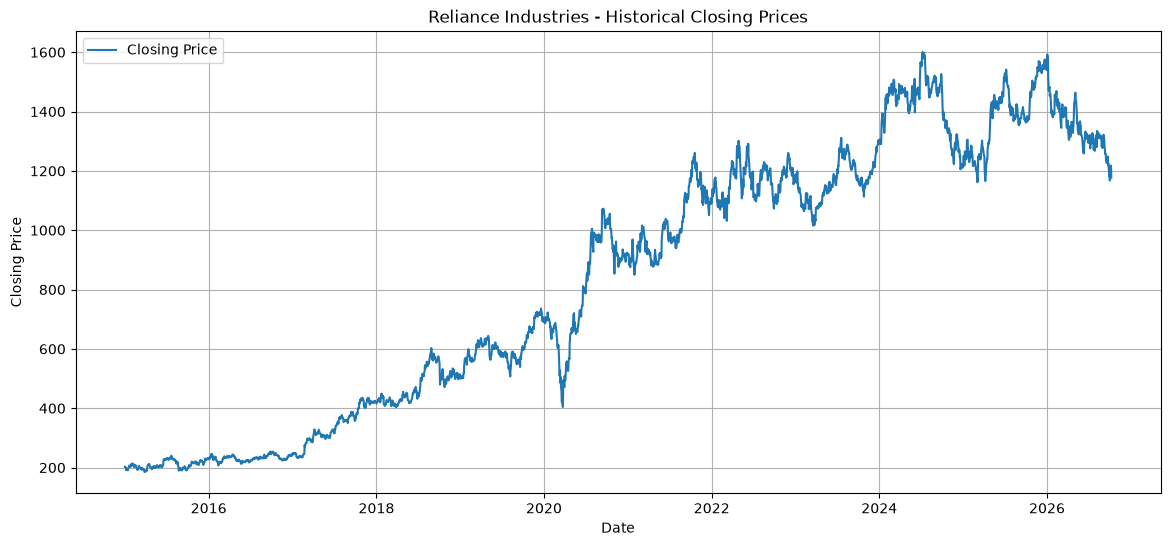

In [9]:
plt.figure(figsize=(14, 6))

plt.plot(df.index, df['Close'], label='Closing Price')

plt.title('Reliance Industries - Historical Closing Prices')
plt.xlabel('Date')
plt.ylabel('Closing Price')

plt.legend()
plt.grid(True)
plt.show()

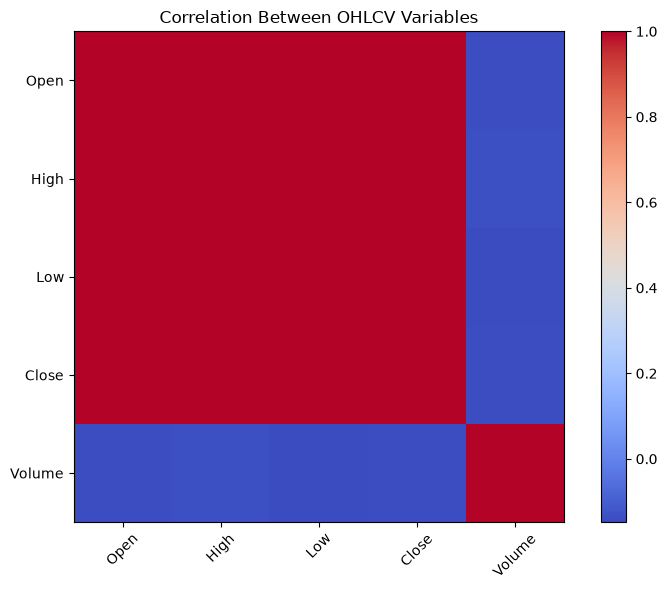

,Open,High,Low,Close,Volume
Open,1.000000,0.999812,0.999795,0.999590,-0.142051
High,0.999812,1.000000,0.999755,0.999839,-0.135125
Low,0.999795,0.999755,1.000000,0.999829,-0.147795
Close,0.999590,0.999839,0.999829,1.000000,-0.141015
Volume,-0.142051,-0.135125,-0.147795,-0.141015,1.000000


In [10]:
correlation = df.corr()

plt.figure(figsize=(8, 6))

plt.imshow(correlation, cmap='coolwarm', interpolation='nearest')

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title('Correlation Between OHLCV Variables')

plt.tight_layout()
plt.show()

correlation

In [11]:
# Create next trading day's closing price as target

df['Target'] = df['Close'].shift(-1)

# Remove the last row because its next-day closing price is unavailable

data = df.dropna().copy()

data.head()

,Open,High,Low,Close,Volume,Target
Date,,,,,,
2015-01-01,202.593277,203.896194,201.987518,202.959000,2963643,202.421829
2015-01-02,203.004715,204.821960,202.136108,202.421829,7331366,200.204575
2015-01-05,202.296112,203.644760,199.804550,200.204575,10103941,191.118393
2015-01-06,198.867371,199.553116,190.181198,191.118393,18627980,195.278610
2015-01-07,191.346985,196.307236,191.324127,195.278610,20720312,192.478470


80% Training and 20% Testing

In [12]:
# Select input features
features = ['Open', 'High', 'Low', 'Close', 'Volume']

X = data[features]
y = data['Target']

# Calculate 80% split
split_index = int(len(data) * 0.80)

# Training data
X_train = X.iloc[:split_index]
y_train = y.iloc[:split_index]

# Testing data
X_test = X.iloc[split_index:]
y_test = y.iloc[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining period:")
print(X_train.index.min(), "to", X_train.index.max())

print("\nTesting period:")
print(X_test.index.min(), "to", X_test.index.max())

Training samples: 2328
Testing samples: 582

Training period:
2015-01-01 00:00:00 to 2024-06-10 00:00:00

Testing period:
2024-06-11 00:00:00 to 2026-10-07 00:00:00


Multilinear Modal


In [13]:
# Import Linear Regression
from sklearn.linear_model import LinearRegression

# Create model
lr_model = LinearRegression()

# Train model
lr_model.fit(X_train, y_train)

print("Multiple Linear Regression trained successfully!")

Multiple Linear Regression trained successfully!


First 10 prediction

In [14]:
# Predict closing prices
lr_predictions = lr_model.predict(X_test)

print("First 10 predictions:")
print(lr_predictions[:10])

First 10 predictions:
[1463.33607857 1462.7842035  1467.13604809 1470.8416694  1481.46382431
 1472.18155648 1466.39929553 1461.20683816 1443.2353675  1448.20529974]


comparison with the original data


In [15]:
lr_results = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': lr_predictions
})

lr_results.head(10)

,Actual Price,Predicted Price
Date,,
2024-06-11,1463.324951,1463.336079
2024-06-12,1465.250000,1462.784203
2024-06-13,1477.550049,1467.136048
2024-06-14,1481.025024,1470.841669
2024-06-18,1458.650024,1481.463824
2024-06-19,1473.699951,1472.181556
2024-06-20,1454.199951,1466.399296
2024-06-21,1441.474976,1461.206838
2024-06-24,1454.150024,1443.235367


Evalutating MLR (MULTI LINEAR REGRESSION)

In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Calculate evaluation metrics
lr_mae = mean_absolute_error(y_test, lr_predictions)

lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))

lr_mape = np.mean(
    np.abs((y_test - lr_predictions) / y_test)
) * 100

# Display results
print("Multiple Linear Regression Performance")
print("---------------------------------------")
print("MAE:", lr_mae)
print("RMSE:", lr_rmse)
print("MAPE:", lr_mape, "%")

Multiple Linear Regression Performance
---------------------------------------
MAE: 14.698835008767908
RMSE: 19.79670031491518
MAPE: 1.0750247211213797 %


Dynamic Regression with AR(1) Errors

In [17]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

Train Dynamic Regression with AR(1)

In [21]:
# Train AR(1) model with numerical indexes

ar1_model = SARIMAX(
    y_train.to_numpy(),
    exog=X_train.to_numpy(),
    order=(1, 0, 0),
    trend='c',
    enforce_stationarity=False
)

ar1_fitted = ar1_model.fit(disp=False)

print("AR(1) model trained successfully!")

AR(1) model trained successfully!


In [22]:
print(ar1_fitted.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 2328
Model:               SARIMAX(1, 0, 0)   Log Likelihood               -9309.528
Date:                Wed, 11 Nov 2026   AIC                          18635.055
Time:                        21:34:20   BIC                          18681.074
Sample:                             0   HQIC                         18651.823
                               - 2328                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0329      0.000    197.776      0.000       0.033       0.033
x1            -0.0561      0.043     -1.309      0.191      -0.140       0.028
x2             0.0509      0.059      0.860      0.3

AR(1) Prediction


In [23]:
ar1_predictions = []

current_model = ar1_fitted

for i in range(len(X_test)):

    forecast = current_model.get_forecast(
        steps=1,
        exog=X_test.iloc[[i]].to_numpy()
    )

    prediction = forecast.predicted_mean[0]

    ar1_predictions.append(prediction)

    current_model = current_model.append(
        endog=[y_test.iloc[i]],
        exog=X_test.iloc[[i]].to_numpy(),
        refit=False
    )

print("AR(1) predictions generated successfully!")

AR(1) predictions generated successfully!


Display result Prediction

In [24]:
ar1_results = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': ar1_predictions
})

ar1_results.head(10)

,Actual Price,Predicted Price
Date,,
2024-06-11,1463.324951,1457.926867
2024-06-12,1465.250000,1464.623522
2024-06-13,1477.550049,1465.874326
2024-06-14,1481.025024,1476.977099
2024-06-18,1458.650024,1481.081439
2024-06-19,1473.699951,1459.425390
2024-06-20,1454.199951,1473.725143
2024-06-21,1441.474976,1454.433927
2024-06-24,1454.150024,1442.419252


Evaluate AR(1)

In [25]:
ar1_mae = mean_absolute_error(y_test, ar1_predictions)

ar1_rmse = np.sqrt(
    mean_squared_error(y_test, ar1_predictions)
)

ar1_mape = np.mean(
    np.abs((y_test.to_numpy() - ar1_predictions) / y_test.to_numpy())
) * 100

print("Dynamic Regression with AR(1) Errors")
print("-------------------------------------")
print("MAE:", ar1_mae)
print("RMSE:", ar1_rmse)
print("MAPE:", ar1_mape, "%")

Dynamic Regression with AR(1) Errors
-------------------------------------
MAE: 13.324323717264583
RMSE: 17.846002606369204
MAPE: 0.9743858037085418 %


Train Dynamic Regression with ARIMA(1,1,1) Errors

In [26]:
# Dynamic Regression with ARIMA(1,1,1) Errors

arima_error_model = SARIMAX(
    y_train.to_numpy(),
    exog=X_train.to_numpy(),
    order=(1, 1, 1),
    trend='t',
    enforce_stationarity=False,
    enforce_invertibility=False
)

arima_error_fitted = arima_error_model.fit(disp=False)

print("Dynamic Regression with ARIMA(1,1,1) Errors trained successfully!")

Dynamic Regression with ARIMA(1,1,1) Errors trained successfully!


Generating prediction of Dynamic regression with ARIMA(1,1,1) Errors

In [27]:
arima_predictions = []

current_model = arima_error_fitted

for i in range(len(X_test)):

    forecast = current_model.get_forecast(
        steps=1,
        exog=X_test.iloc[[i]].to_numpy()
    )

    prediction = forecast.predicted_mean[0]

    arima_predictions.append(prediction)

    # Update model using actual observation
    current_model = current_model.append(
        endog=[y_test.iloc[i]],
        exog=X_test.iloc[[i]].to_numpy(),
        refit=False
    )

print("ARIMA-error predictions generated successfully!")

ARIMA-error predictions generated successfully!


displaying of prediction and comparision with original price


In [28]:
arima_results = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': arima_predictions
})

arima_results.head(10)

,Actual Price,Predicted Price
Date,,
2024-06-11,1463.324951,1545.218975
2024-06-12,1465.250000,1408.802798
2024-06-13,1477.550049,1466.992255
2024-06-14,1481.025024,1410.615285
2024-06-18,1458.650024,1471.791298
2024-06-19,1473.699951,1580.224769
2024-06-20,1454.199951,1376.029160
2024-06-21,1441.474976,1568.956762
2024-06-24,1454.150024,1485.027430


Evaluate ARIMA-error model

In [29]:
arima_mae = mean_absolute_error(y_test, arima_predictions)

arima_rmse = np.sqrt(
    mean_squared_error(y_test, arima_predictions)
)

arima_mape = np.mean(
    np.abs(
        (y_test.to_numpy() - arima_predictions)
        / y_test.to_numpy()
    )
) * 100

print("Dynamic Regression with ARIMA(1,1,1) Errors")
print("--------------------------------------------")
print("MAE:", arima_mae)
print("RMSE:", arima_rmse)
print("MAPE:", arima_mape, "%")

Dynamic Regression with ARIMA(1,1,1) Errors
--------------------------------------------
MAE: 71.91798242278777
RMSE: 94.98440711401345
MAPE: 5.254405379374042 %


modal 4 :Dynamic Regression with Lagged Predictors

In [30]:
# Create lagged predictors

data_lagged = data.copy()

data_lagged['Close_Lag1'] = df['Close'].shift(1)
data_lagged['Volume_Lag1'] = df['Volume'].shift(1)

# Remove rows containing NaN values
data_lagged = data_lagged.dropna()

# Display dataset
data_lagged.head()

,Open,High,Low,Close,Volume,Target,Close_Lag1,Volume_Lag1
Date,,,,,,,,
2015-01-02,203.004715,204.821960,202.136108,202.421829,7331366,200.204575,202.959000,2963643.0
2015-01-05,202.296112,203.644760,199.804550,200.204575,10103941,191.118393,202.421829,7331366.0
2015-01-06,198.867371,199.553116,190.181198,191.118393,18627980,195.278610,200.204575,10103941.0
2015-01-07,191.346985,196.307236,191.324127,195.278610,20720312,192.478470,191.118393,18627980.0
2015-01-08,196.604385,197.244431,192.044159,192.478470,19872227,196.650101,195.278610,20720312.0


training and testing

In [31]:
# Select features for Model 4

lag_features = [
    'Open',
    'High',
    'Low',
    'Close',
    'Volume',
    'Close_Lag1',
    'Volume_Lag1'
]

X_lag = data_lagged[lag_features]
y_lag = data_lagged['Target']

# Chronological 80-20 split
split_index_lag = int(len(data_lagged) * 0.80)

X_train_lag = X_lag.iloc[:split_index_lag]
y_train_lag = y_lag.iloc[:split_index_lag]

X_test_lag = X_lag.iloc[split_index_lag:]
y_test_lag = y_lag.iloc[split_index_lag:]

print("Training samples:", len(X_train_lag))
print("Testing samples:", len(X_test_lag))

print("\nTraining period:")
print(X_train_lag.index.min(), "to", X_train_lag.index.max())

print("\nTesting period:")
print(X_test_lag.index.min(), "to", X_test_lag.index.max())

Training samples: 2327
Testing samples: 582

Training period:
2015-01-02 00:00:00 to 2024-06-10 00:00:00

Testing period:
2024-06-11 00:00:00 to 2026-10-07 00:00:00


Train Model 4: Linear Regression with Lagged Predictors

In [32]:
# Create Linear Regression model with lagged predictors

lag_model = LinearRegression()

# Train the model
lag_model.fit(X_train_lag, y_train_lag)

print("Dynamic Regression with Lagged Predictors trained successfully!")

Dynamic Regression with Lagged Predictors trained successfully!


generate prediction

In [33]:
# Generate predictions
lag_predictions = lag_model.predict(X_test_lag)

print("First 10 predictions:")
print(lag_predictions[:10])

First 10 predictions:
[1465.07208537 1461.65987172 1466.45264625 1469.78251449 1480.72180988
 1474.01532654 1465.054453   1464.19352161 1445.52423581 1446.89631781]


displaying comparision between actual and predicted closing price


In [34]:
lag_results = pd.DataFrame({
    'Actual Price': y_test_lag,
    'Predicted Price': lag_predictions
})

lag_results.head(10)

,Actual Price,Predicted Price
Date,,
2024-06-11,1463.324951,1465.072085
2024-06-12,1465.250000,1461.659872
2024-06-13,1477.550049,1466.452646
2024-06-14,1481.025024,1469.782514
2024-06-18,1458.650024,1480.721810
2024-06-19,1473.699951,1474.015327
2024-06-20,1454.199951,1465.054453
2024-06-21,1441.474976,1464.193522
2024-06-24,1454.150024,1445.524236


Evaluating Dynamic Regression with Lagged Predictors

In [35]:
lag_mae = mean_absolute_error(y_test_lag, lag_predictions)

lag_rmse = np.sqrt(
    mean_squared_error(y_test_lag, lag_predictions)
)

lag_mape = np.mean(
    np.abs(
        (y_test_lag.to_numpy() - lag_predictions)
        / y_test_lag.to_numpy()
    )
) * 100

print("Dynamic Regression with Lagged Predictors")
print("------------------------------------------")
print("MAE:", lag_mae)
print("RMSE:", lag_rmse)
print("MAPE:", lag_mape, "%")

Dynamic Regression with Lagged Predictors
------------------------------------------
MAE: 15.302854305101107
RMSE: 20.540907698752715
MAPE: 1.1191085035445694 %


Comparision between all four dynamic regression modals

In [36]:
comparison = pd.DataFrame({
    'Model': [
        'Multiple Linear Regression',
        'Dynamic Regression AR(1)',
        'Dynamic Regression ARIMA(1,1,1)',
        'Dynamic Regression with Lagged Predictors'
    ],

    'MAE': [
        lr_mae,
        ar1_mae,
        arima_mae,
        lag_mae
    ],

    'RMSE': [
        lr_rmse,
        ar1_rmse,
        arima_rmse,
        lag_rmse
    ],

    'MAPE': [
        lr_mape,
        ar1_mape,
        arima_mape,
        lag_mape
    ]
})

comparison

,Model,MAE,RMSE,MAPE
0,Multiple Linear Regression,14.698835,19.796700,1.075025
1,Dynamic Regression AR(1),13.324324,17.846003,0.974386
2,"Dynamic Regression ARIMA(1,1,1)",71.917982,94.984407,5.254405
3,Dynamic Regression with Lagged Predictors,15.302854,20.540908,1.119109


AR(1) performed better than ordinary Linear Regression.
ARIMA(1,1,1) performed considerably worse.
Adding lagged predictors did not improve the baseline model.

In [ ]:
Visualizing model performance

MAE Comparision

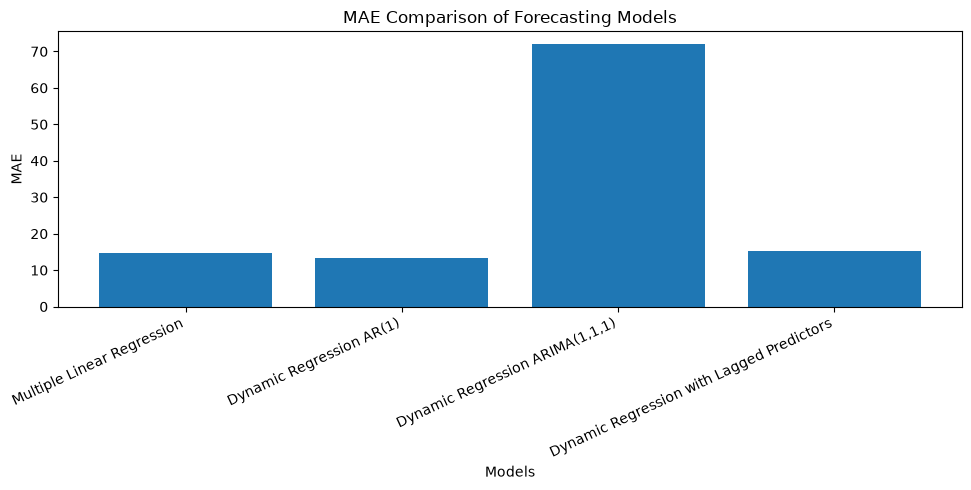

In [37]:
# Plot MAE comparison
plt.figure(figsize=(10, 5))

plt.bar(comparison['Model'], comparison['MAE'])

plt.title('MAE Comparison of Forecasting Models')
plt.xlabel('Models')
plt.ylabel('MAE')
plt.xticks(rotation=25, ha='right')

plt.tight_layout()
plt.show()

RMSE comparison

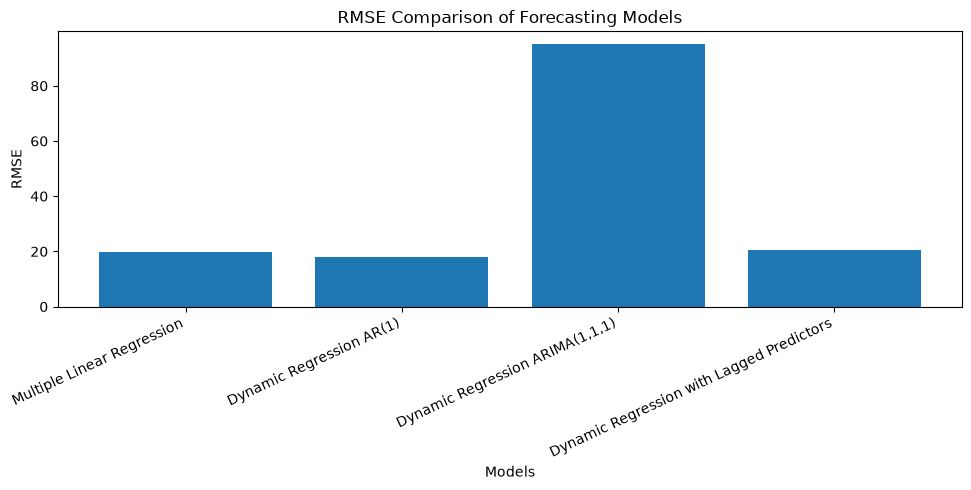

In [38]:
plt.figure(figsize=(10, 5))

plt.bar(comparison['Model'], comparison['RMSE'])

plt.title('RMSE Comparison of Forecasting Models')
plt.xlabel('Models')
plt.ylabel('RMSE')
plt.xticks(rotation=25, ha='right')

plt.tight_layout()
plt.show()

MAPE Comparision

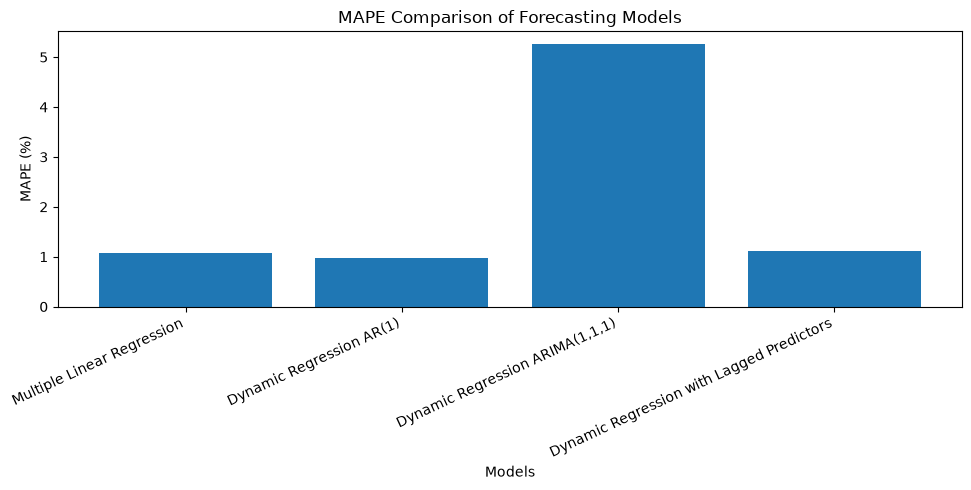

In [39]:
plt.figure(figsize=(10, 5))

plt.bar(comparison['Model'], comparison['MAPE'])

plt.title('MAPE Comparison of Forecasting Models')
plt.xlabel('Models')
plt.ylabel('MAPE (%)')
plt.xticks(rotation=25, ha='right')

plt.tight_layout()
plt.show()

AR(1) has better result than rest of the modals

Actual vs Predicted Closing Prices AR(1)

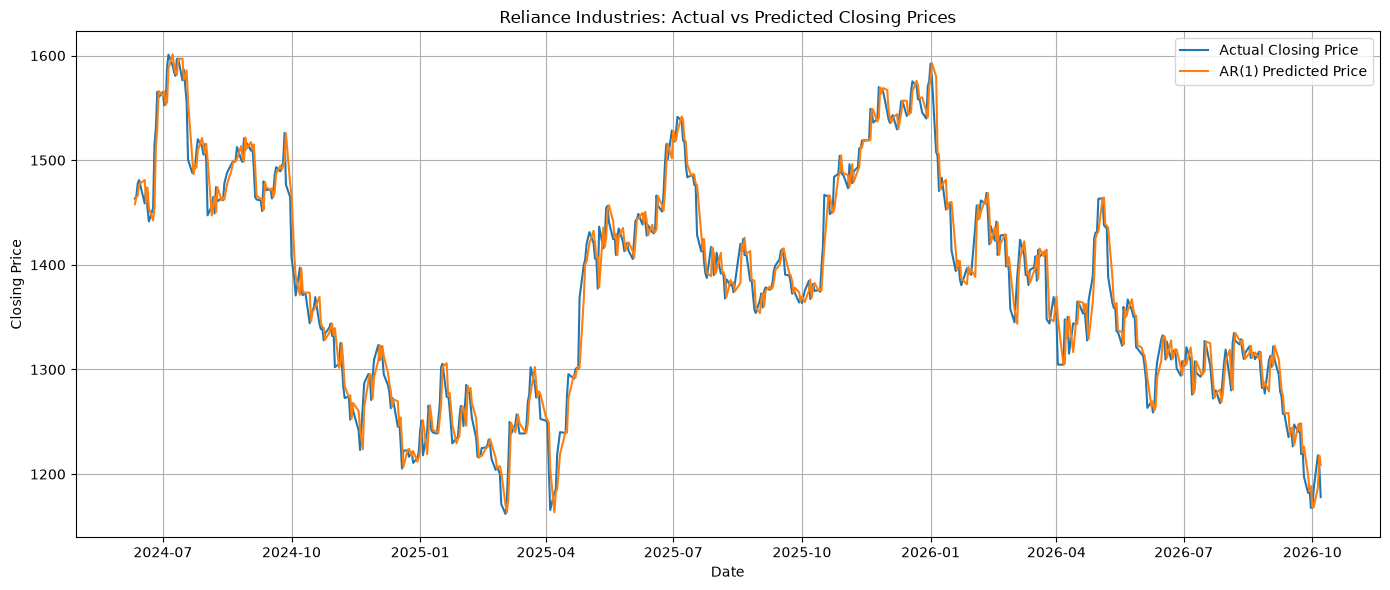

In [40]:
plt.figure(figsize=(14, 6))

plt.plot(
    y_test.index,
    y_test.values,
    label='Actual Closing Price'
)

plt.plot(
    y_test.index,
    ar1_predictions,
    label='AR(1) Predicted Price'
)

plt.title('Reliance Industries: Actual vs Predicted Closing Prices')
plt.xlabel('Date')
plt.ylabel('Closing Price')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

calculating residuals for AR(1)

In [41]:
# Calculate residuals for AR(1) model

ar1_residuals = y_test.to_numpy() - ar1_predictions

print("Residuals calculated successfully!")
print("First 10 residuals:")
print(ar1_residuals[:10])

Residuals calculated successfully!
First 10 residuals:
[  5.39808464   0.62647827  11.67572308   4.04792531 -22.43141488
  14.27456117 -19.52519221 -12.95895105  11.73077214  59.49274518]


Plot residuals over time

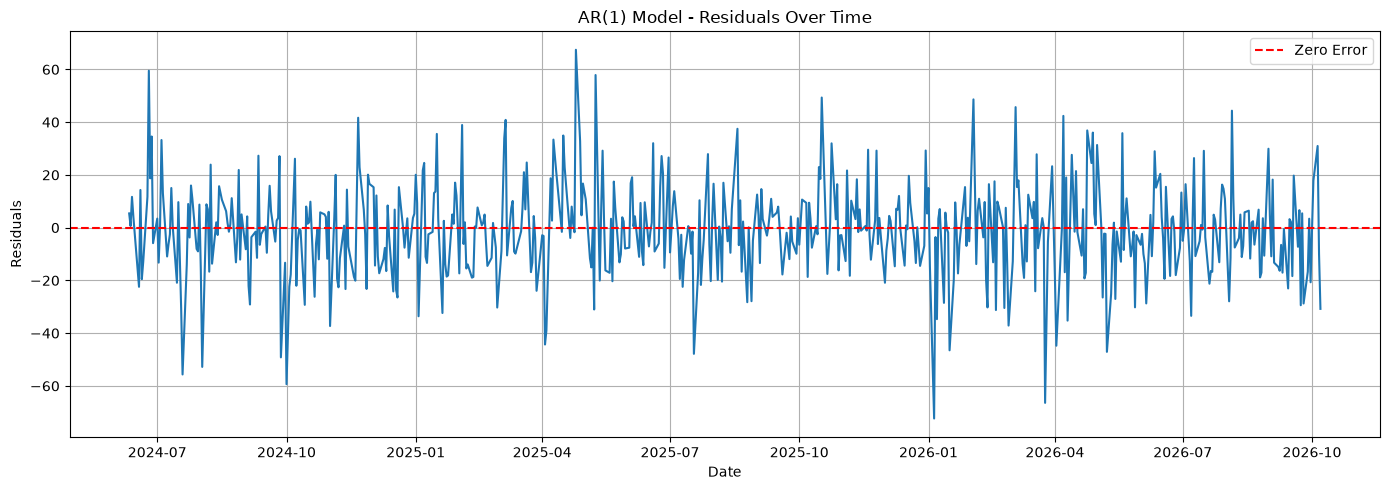

In [42]:
plt.figure(figsize=(14, 5))

plt.plot(y_test.index, ar1_residuals)

plt.axhline(
    y=0,
    color='red',
    linestyle='--',
    label='Zero Error'
)

plt.title('AR(1) Model - Residuals Over Time')
plt.xlabel('Date')
plt.ylabel('Residuals')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Residual Autocorrelation (ACF Plot)

<Figure size 1200x500 with 0 Axes>

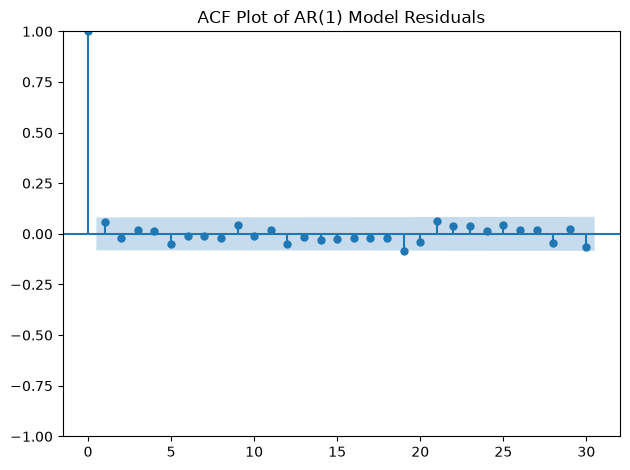

In [43]:
from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(12, 5))

plot_acf(ar1_residuals, lags=30)

plt.title('ACF Plot of AR(1) Model Residuals')
plt.tight_layout()
plt.show()

Ljung-Box Test

In [44]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# Perform Ljung-Box test
ljung_box_results = acorr_ljungbox(
    ar1_residuals,
    lags=[10, 20],
    return_df=True
)

print("Ljung-Box Test Results")
print("----------------------")
print(ljung_box_results)

Ljung-Box Test Results
----------------------
      lb_stat  lb_pvalue
10   5.503164   0.855137
20  14.349215   0.812358


FINAL RESULT AND BEST MODAL

In [45]:
# Identify the best model using MAE
best_model = comparison.loc[comparison['MAE'].idxmin()]

print("BEST PERFORMING MODEL")
print("---------------------")

print("Model:", best_model['Model'])
print("MAE:", best_model['MAE'])
print("RMSE:", best_model['RMSE'])
print("MAPE:", best_model['MAPE'], "%")

BEST PERFORMING MODEL
---------------------
Model: Dynamic Regression AR(1)
MAE: 13.324323717264583
RMSE: 17.846002606369204
MAPE: 0.9743858037085418 %
